# Multi-Fidelity Kolmogorov Arnold Networks
Set of examples to show utility of KAN networks applied to MF datasets

### Initialization
Add the Surrogate Modeling module and setup the notebook

In [1]:
# Boilerplate for automatic reloading of modules on run and connecting to paths of local code.

%load_ext autoreload
%autoreload 2
%matplotlib widget

import matplotlib.pyplot as plt
import numpy as np

from SurrogateModels import mfkans

### Function Choice
Set the example function to fit, each has a set high and low fidelity function.

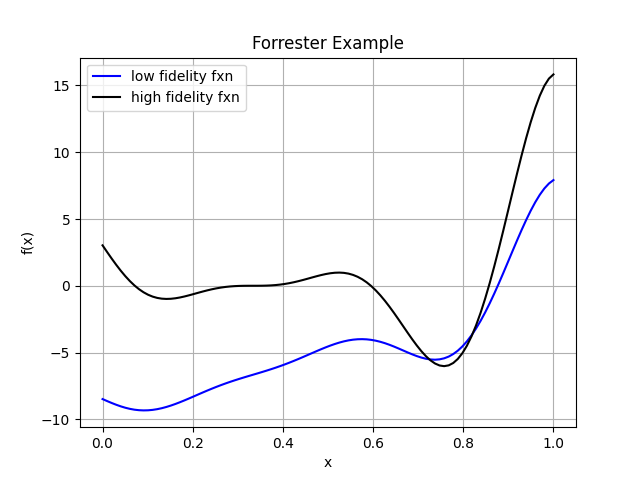

In [2]:
import multi_fidelity_functions
import matplotlib.pyplot as plt

mf_example = multi_fidelity_functions.ForresterExample()
mf_example.plot_functions(name = mf_example.name)
plt.grid()
plt.legend()
plt.show()

### Dataset Generation
Sample the high and low fidelity functions to generate a dataset to fit

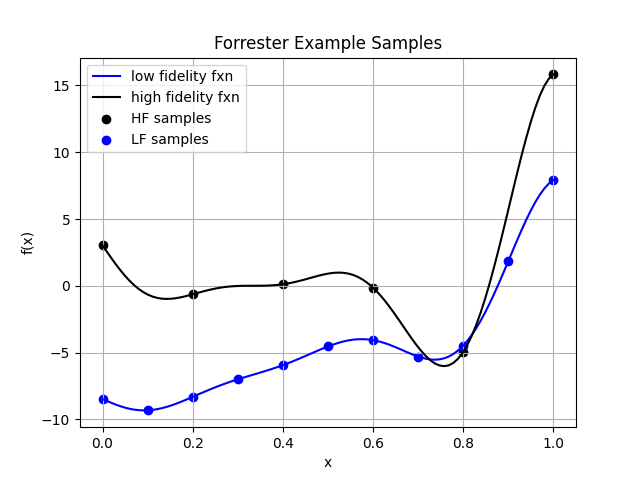

In [3]:
# Define the example function bounds and dimensions here
dim = mf_example.dimensions
xmin = mf_example.bounds[0][0]
xmax = mf_example.bounds[0][1]

n_lf = 11 # number of low fidelity points
n_hf = 6 # number of high fidelity points
n_test = 40 # number of test points

# Generate the analytical functions
hf_fxn = mf_example.high_fidelity
lf_fxn = mf_example.low_fidelity

X_lf = np.linspace(xmin,xmax,n_lf,dtype=np.float32).reshape(-1,1)
y_lf = lf_fxn(X_lf)

X_hf = np.linspace(xmin,xmax,n_hf,dtype=np.float32).reshape(-1,1)
y_hf = hf_fxn(X_hf)

X_test = np.linspace(xmin,xmax,n_test,dtype=np.float32).reshape(-1,1)
y_lf_test = lf_fxn(X_test)
y_hf_test = hf_fxn(X_test)

plot_name = mf_example.name + " Samples"

mf_example.plot_functions(name = plot_name)

plt.figure(plot_name)
plt.title(plot_name)
plt.scatter(X_hf, y_hf, color = "black", label = "HF samples", marker = "o")
plt.scatter(X_lf, y_lf, color = "blue", label = "LF samples", marker = "o")

plt.grid()
plt.legend()
plt.show()

### Function Fit
Fit the dataset using the KAN network

In [9]:
y_test = mf_example.low_fidelity(X_test)
forrester_model = mfkans.KANModel(X_lf,y_lf,X_test,y_test,width=[1,2,1])

checkpoint directory created: ./model
saving model version 0.0


| train_loss: 2.64e-02 | test_loss: 6.19e+00 | reg: 2.72e+01 | : 100%|█| 100/100 [00:11<00:00,  9.00

saving model version 0.1


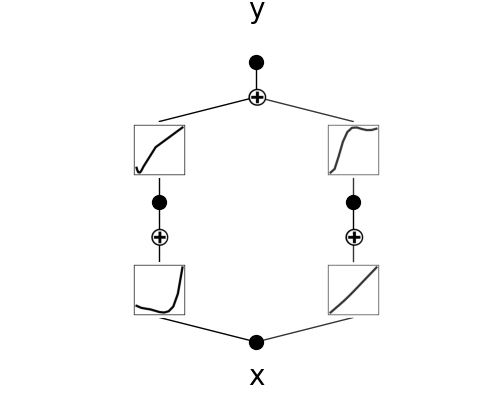

In [10]:
forrester_model.plot(in_vars=['x'],out_vars=['y'],title="Forrester KAN Model")

In [13]:

my_points = forrester_model.evaluate(X_hf[:])
print(my_points)

tensor([[-8.4932],
        [-8.3489],
        [-5.8905],
        [-4.0462],
        [-4.4775],
        [ 7.9117]])


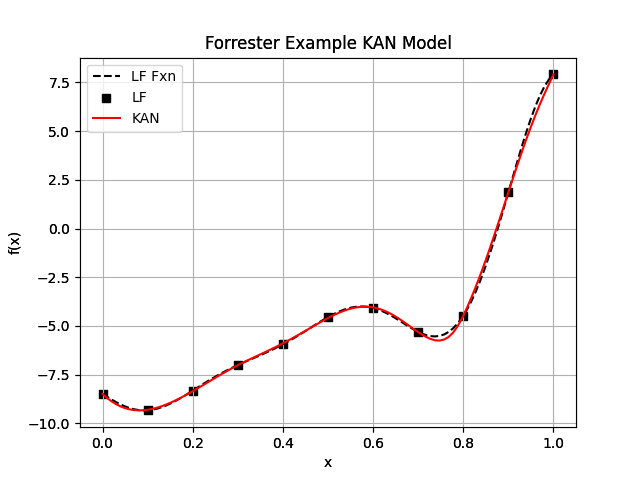

In [15]:
plot_name = mf_example.name + " KAN Model"


ax = mf_example.plot_low_fidelity(
    name=plot_name, color="black", label="LF Fxn", linestyle="dashed"
)

ax = forrester_model.plot_data(
    name=plot_name,
    color="black",
    label="LF",
    marker="s",
    ax = ax
)
forrester_model.plot_model(
    mf_example.bounds, name=plot_name, color="red", label="KAN", linestyle="solid",ax=ax
)
plt.grid()
plt.show()

### MF KAN Model
Generate a mf model of the Forrester data using the MF KAN formulation

In [ ]:
# MFKAN Model for forrester mf example
forrester_mf_model = mfkans.MFKANModel(
    x_lf=X_lf,
    y_lf=y_lf,
    x_lf_test=X_test,
    y_lf_test=y_lf_test,
    x_hf=X_hf,
    y_hf=y_hf,
    x_hf_test=X_test,
    y_hf_test=y_hf_test,
    spline_order_lf=3,
    spline_order_mf=3,
    width_lf=[1, 2, 1],
    width_mf=[1, 2, 1],
    grid_lf=3,
    grid_mf=3,
    opt_lf="LBFGS",
    opt_mf="LBFGS",
    n_iter_lf=100,
    n_iter_mf=100,
)

checkpoint directory created: ./model
saving model version 0.0


| train_loss: 1.61e-02 | test_loss: 6.19e+00 | reg: 3.88e+01 | : 100%|█| 100/100 [00:09<00:00, 10.04


saving model version 0.1
[[ 0.        -8.4869375]
 [ 0.2       -8.320393 ]
 [ 0.4       -5.980785 ]
 [ 0.6       -4.087724 ]
 [ 0.8       -4.481118 ]
 [ 1.         7.9150724]]
checkpoint directory created: ./model
saving model version 0.0


| train_loss: 5.35e-06 | test_loss: 7.14e+00 | reg: 9.19e+02 | : 100%|█| 100/100 [00:08<00:00, 12.14

saving model version 0.1


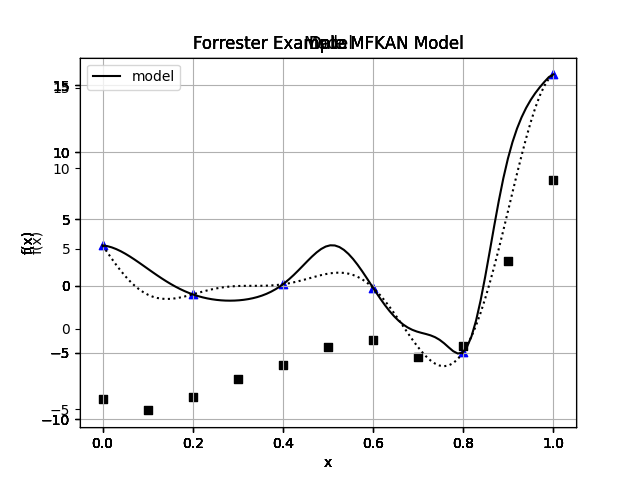

In [ ]:
plot_name = mf_example.name + " MFKAN Model"

ax = forrester_mf_model.plot_model(bounds=mf_example.bounds, name=plot_name)
ax = forrester_mf_model.plot_data(name=plot_name, ax=ax)
ax = mf_example.plot_high_fidelity(name=plot_name,linestyle="dotted", ax=ax)
ax.legend()
plt.grid()
plt.show()